Find god taksonomi - https://www.census.gov/naics/?input=71&chart=2017 ? foursquare?



In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
import statsmodels.api as sm
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [2]:
# config
sns.set_theme(style="ticks")
pl.Config.set_engine_affinity("streaming")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path, read_only=True)

In [3]:
query = """
    WITH v AS (
        SELECT ID_STORE, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
        FROM visits
        GROUP BY ID_STORE
    ), h AS (
        SELECT c.CELL_ID, AVG(TMEAN) AS AVG_TMEAN
        FROM prism_cells c
        JOIN prism_t_daily t ON c.CELL_ID = t.CELL_ID
        GROUP BY c.cell_id
    )
    SELECT p.*, v.TOTAL_VISITORS AS VISITORS, AVG_TMEAN
    FROM pois p
    JOIN v ON p.ID_STORE = v.ID_STORE
    LEFT JOIN h ON p.CELL_ID = h.CELL_ID
    WHERE CBSAFP = '35620'
"""
pois_dim = con.sql(query).pl().with_columns(
    pl.len().over("TOP_CATEGORY").alias("NUM_CATEGORY_POIS")
)
top_categories = set(pois_dim.group_by("TOP_CATEGORY").len().top_k(6, by="len")["TOP_CATEGORY"])
pois_dim = pois_dim.with_columns(
    pl.when(pl.col("TOP_CATEGORY").is_in(top_categories))
        .then(pl.col("TOP_CATEGORY"))
        .otherwise(pl.lit("Other"))
        .alias("TOP_CATEGORY_K")
)
pois_dim.head()

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",f64,u32,str
"""5975348""","""340030582004""","""35620""","""A1_XPOF-RH""","""Row House""","""Row House""","""275 Pascack Road""","""Township Of Washington""","""NJ""","""US""","""713940""","""Other Amusement and Recreation…","""Fitness and Recreational Sport…",2019-10-14,2038-01-01,-74.063132,40.985433,"b""\x01\x01\x00\x00\x000\xd5\xccZ\x0a\x84R\xc0\x00qW\xaf""~D@""",301892,2424,11.82793,10334,"""Other"""
"""5985132""","""340399800001""","""35620""","""A1_NEWBL-A""","""New Balance""","""New Balance, Inc.""","""651 Kapkowski Road""","""Elizabeth""","""NJ""","""US""","""448210""","""Shoe Stores ""","""Shoe Stores """,1970-01-01,2038-01-01,-74.169972,40.658924,"b""\x01\x01\x00\x00\x00\x16O=\xd2\xe0\x8aR\xc0>\x04U\xa3WTD@""",313130,83780,13.265868,2138,"""Other"""
"""5989272""","""340030154012""","""35620""","""A1_JENNYC-A""","""Jenny Craig""","""Jenny Craig, Inc.""","""106 Grand Avenue, Suite 110""","""Englewood""","""NJ""","""US""","""812191""","""Personal Care Services ""","""Diet and Weight Reducing Cente…",1970-01-01,2038-01-01,-73.975835,40.889694,"b""\x01\x01\x00\x00\x00\xbf\xf3\x8b\x12t~R\xc0-wf\x82\xe1qD@""",306110,2444,12.277328,15702,"""Personal Care Services """
"""6010091""","""360594088006""","""35620""","""A1_HOTWORX-A""","""HOTWORX""","""HOTWORX""","""635 Hicksville Rd""","""Bethpage""","""NY""","""US""","""713940""","""Other Amusement and Recreation…","""Fitness and Recreational Sport…",1970-01-01,2038-01-01,-73.497043,40.741797,"b""\x01\x01\x00\x00\x00+mq\x8d\xcf_R\xc0\xad\xa2?4\xf3^D@""",310336,30201,12.434945,10334,"""Other"""
"""6021195""","""360870113052""","""35620""","""A1_MALL-A""","""Mall""","""Rockland Plaza (Nanuet, NY)""","""Route 59 West & Middletown Roa…","""Nanuet""","""NY""","""US""","""531120""","""Lessors of Real Estate""","""Lessors of Nonresidential Buil…",1970-01-01,2038-01-01,-74.013082,41.098701,"b""\x01\x01\x00\x00\x00\xa4\x8a\xe2U\xd6\x80R\xc0\x8f\x8a\xff;\xa2\x8cD@""",299084,637681,11.496595,3390,"""Other"""


We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

In [4]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    ), filtered_pois AS (
        with x as (
            select
                v.ID_STORE, HOME_GEOID,
                SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
                COUNT(*) AS NUM_WEEKS
            from block_group_visits v
            join pois p on v.ID_STORE = p.ID_STORE
            where VISITOR_COUNTS >= 10
              and cbsafp = '35620'
            group by v.ID_STORE, HOME_GEOID
        )
        select 
            ID_STORE
        from x
        where NUM_WEEKS >= 5
          and VISITOR_COUNTS >= 100
        group by ID_STORE
        having COUNT(*) >= 10
    )
    SELECT 
        v.ID_STORE, INCOME_GROUP, 
        SUM(VISITOR_COUNTS) AS TOTAL_VISITORS, 
        COUNT(*) AS NUM_WEEKS
    FROM block_group_visits v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (SELECT ID_STORE FROM filtered_pois)
    GROUP BY v.ID_STORE, INCOME_GROUP
"""
poi_group_visits = con.sql(query).pl()
poi_visits = (
    poi_group_visits
        .sort("INCOME_GROUP")
        .pivot("INCOME_GROUP", index="ID_STORE", column_naming="combine")
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
)
poi_visits.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64
"""10140941""",37434,79205,215511,186940,415,599,713,975,519090,0.072115,0.152584,0.415171,0.36013,0.367068
"""8276807""",2193,2464,17067,10617,74,91,212,281,32341,0.067809,0.076188,0.52772,0.328283,0.474671
"""8750103""",20791,8299,4546,5557,124,53,26,33,39193,0.530477,0.211747,0.11599,0.141786,0.37397
"""9804507""",31648,13183,7881,2789,1297,698,402,164,55501,0.570224,0.237527,0.141997,0.050251,0.426965
"""5069587""",45512,97889,42644,77688,677,873,736,937,263733,0.172568,0.371167,0.161694,0.294571,0.220984


In [5]:
pois = pois_dim.join(poi_visits, on="ID_STORE")

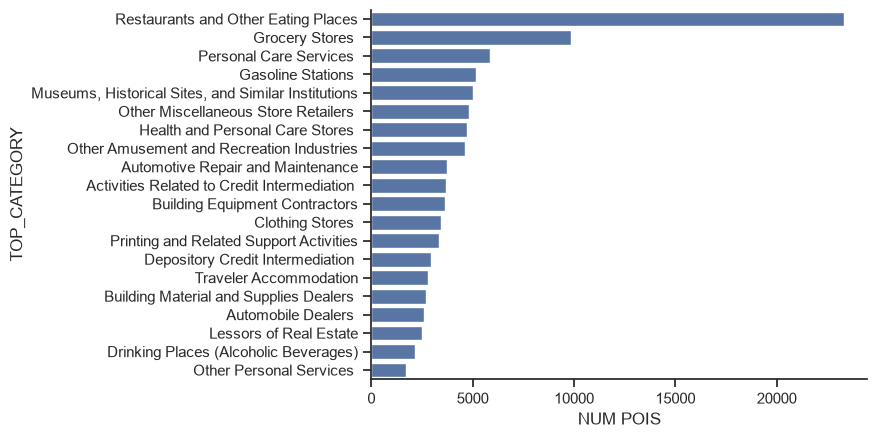

In [6]:
ax = sns.barplot(
    pois.group_by("TOP_CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="TOP_CATEGORY",
    x="len"
)
ax.set_xlabel("NUM POIS")
sns.despine()

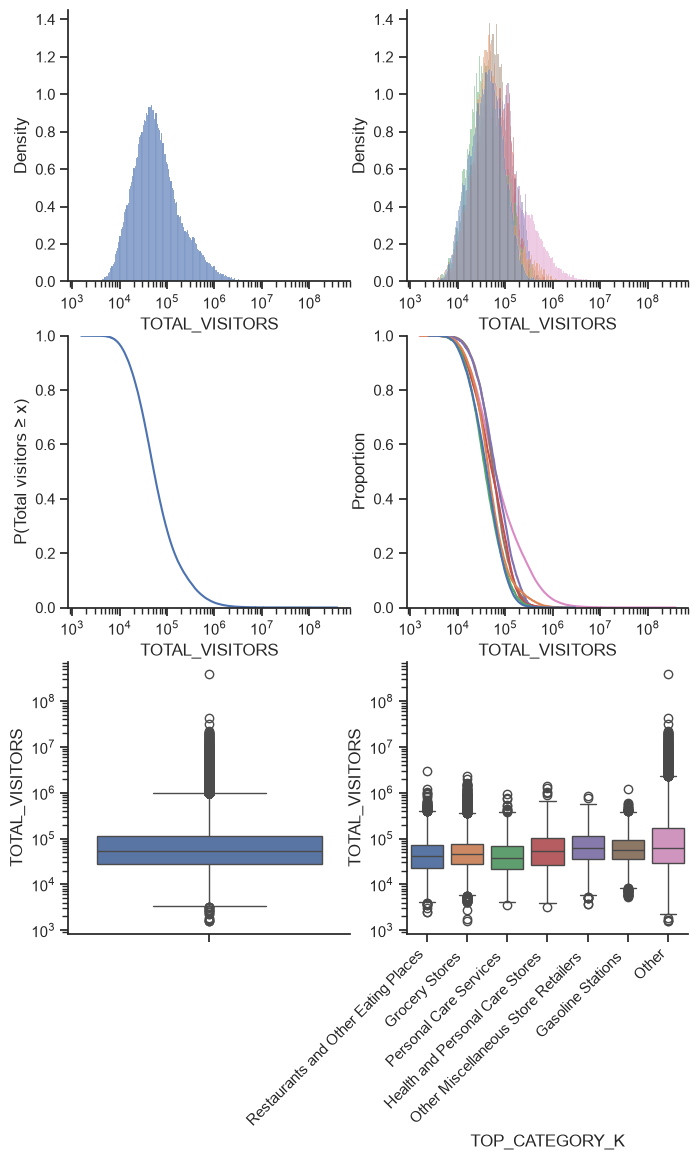

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    stat="density",
    log_scale=True,
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    log_scale=True,
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    complementary=True,
    log_scale=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    complementary=True,
    log_scale=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(Total visitors ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

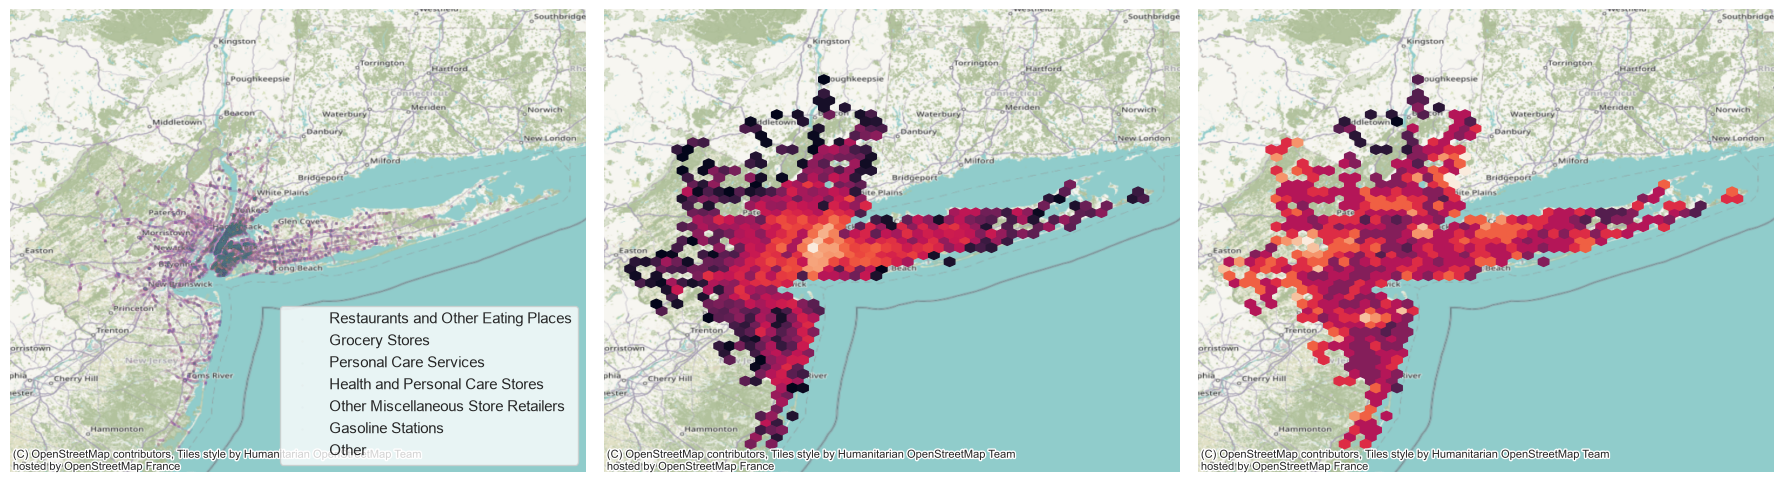

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharex=True, sharey=True)

for i, ((label,), g) in enumerate(pois.sort("NUM_CATEGORY_POIS", descending=True).group_by("TOP_CATEGORY_K", maintain_order=True)):
    axes[0].scatter(g["LONGITUDE"], g["LATITUDE"], s=.1, alpha=.05, label=label, zorder=10-i)
axes[0].legend()
    
axes[1].hexbin(pois["LONGITUDE"], pois["LATITUDE"], mincnt=5, bins="log", gridsize=(50,30))
axes[2].hexbin(pois["LONGITUDE"], pois["LATITUDE"], pois["SEGREGATION"], mincnt=5, bins=10, gridsize=(50,30))

for ax in axes:
    cx.add_basemap(ax, zoom='auto', crs='EPSG:4326')
    ax.set_axis_off()
fig.tight_layout()

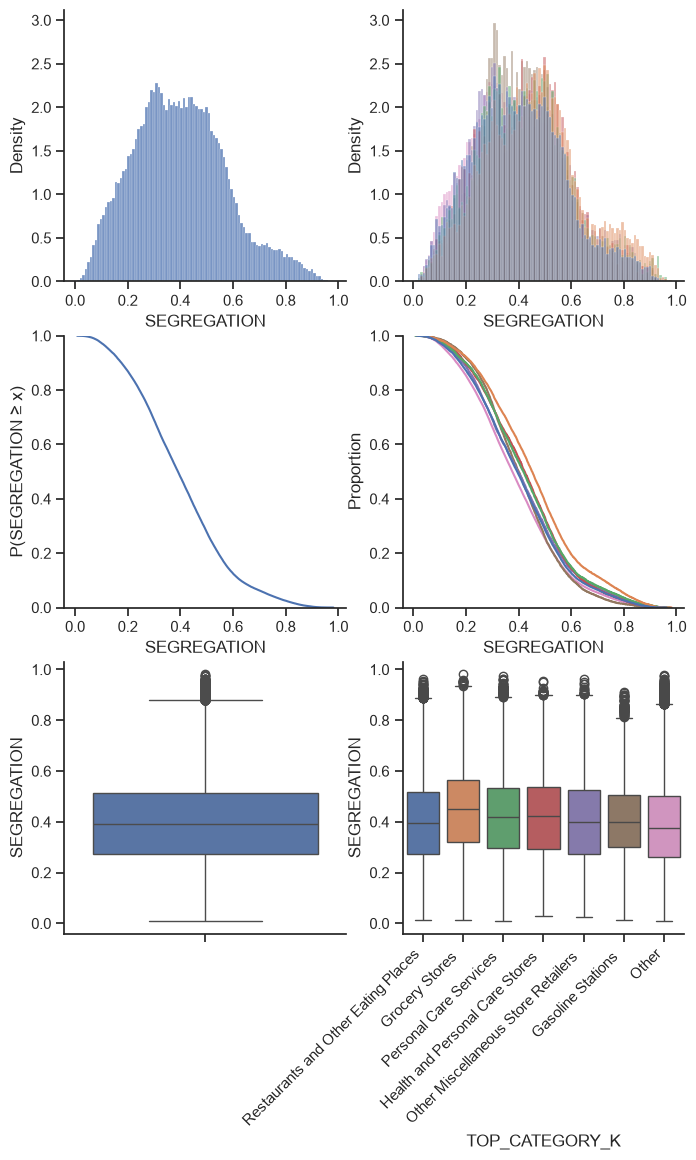

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    stat="density",
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    complementary=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    complementary=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(SEGREGATION ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="SEGREGATION",
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="SEGREGATION",
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

In [10]:
categories = pois.group_by("TOP_CATEGORY").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS")
)
top_categories = pl.concat([
    categories.filter(pl.col("NUM_POIS") >= 100).bottom_k(5, by="W_SEGREGATION"),
    categories.filter(pl.col("NUM_POIS") >= 100).top_k(5, by="W_SEGREGATION"),
])

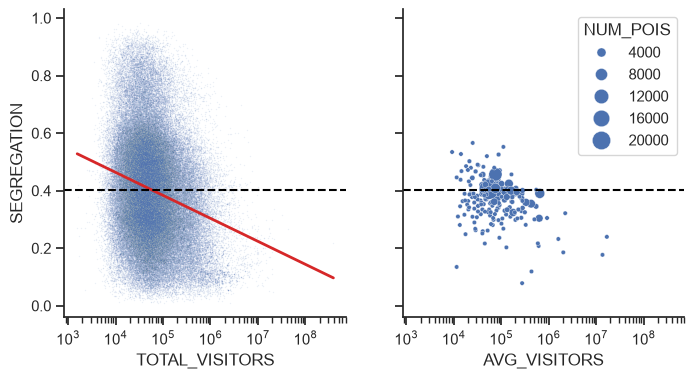

In [11]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))

sns.scatterplot(
    pois.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    alpha=.1,
    s=1,
    ax=axes[0]
)
sns.scatterplot(
    categories.to_pandas(),
    x="AVG_VISITORS",
    y="SEGREGATION",
    size="NUM_POIS",
    sizes=(10, 200),
    ax=axes[1]
)

fit_data = pois.select(pl.col("TOTAL_VISITORS").cast(pl.Int32), "SEGREGATION").drop_nulls()
X = sm.add_constant(np.log10(fit_data["TOTAL_VISITORS"]))
model = sm.OLS(fit_data["SEGREGATION"], X).fit()
x_pred = np.geomspace(
    fit_data["TOTAL_VISITORS"].min(),
    fit_data["TOTAL_VISITORS"].max(),
    200,
)
y_pred = model.predict(
    sm.add_constant(np.log10(x_pred))
)
axes[0].plot(
    x_pred,
    y_pred,
    color="tab:red",
    linewidth=2,
    label=f"OLS ($R^2$ = {model.rsquared:.3f})",
)

mean_seg = pois["SEGREGATION"].mean()
for ax in axes:
    ax.set_xscale("log")
    ax.axhline(mean_seg, color="black", ls="--")
sns.despine()

<Axes: xlabel='AVG_TMEAN', ylabel='SEGREGATION'>

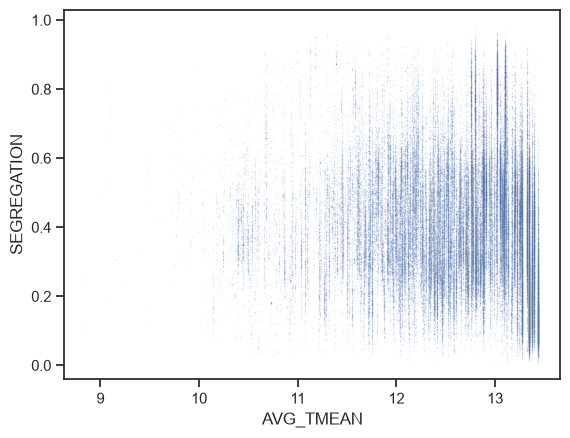

In [12]:
sns.scatterplot(
    pois.to_pandas(),
    x="AVG_TMEAN",
    y="SEGREGATION",
    alpha=.1,
    s=1,
)

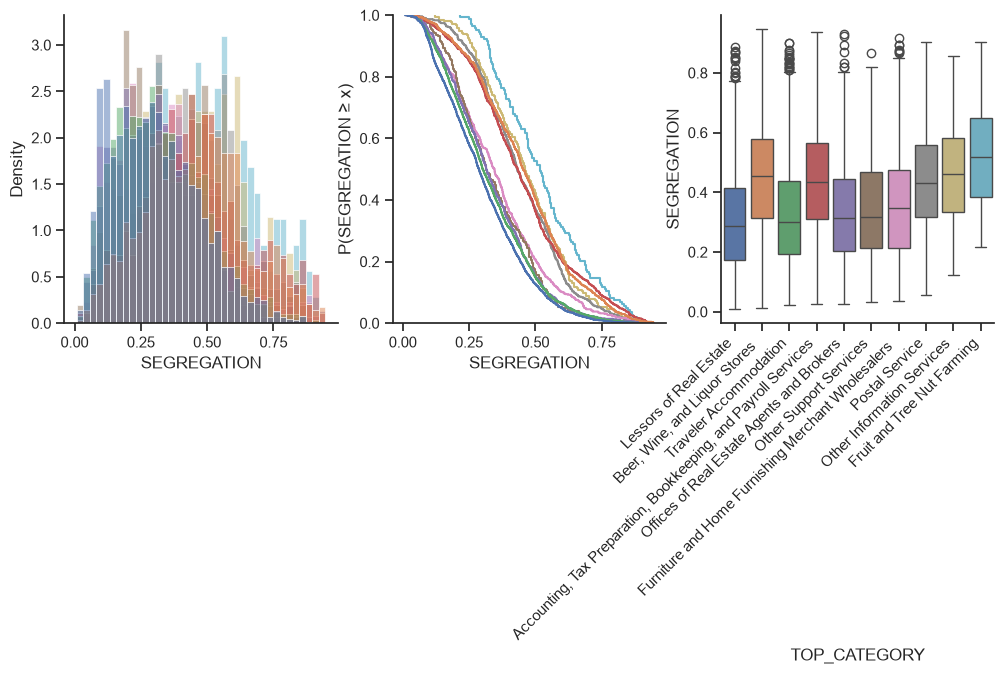

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

category_set = set(top_categories["TOP_CATEGORY"])
pois_pd = pois.filter(pl.col("TOP_CATEGORY").is_in(category_set)).with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),
).sort("SEGREGATION").to_pandas()

sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0],
    legend=False
)

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    complementary=True,
    ax=axes[1],
    legend=False,
)
axes[1].set_ylabel("P(SEGREGATION ≥ x)")

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY",
    y="SEGREGATION",
    ax=axes[2],
    hue="TOP_CATEGORY",
    legend=False
)
axes[2].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

## Data is messed up exploration

In [14]:
pois.filter(
    pl.col("TOTAL_VISITORS") > 10_000,
    pl.col("SEGREGATION") == 1
)

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",f64,u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64


In [15]:
con.sql("""
    SELECT *
    FROM block_group_visits
    WHERE ID_STORE = '8275101'
""").pl()

HOME_GEOID,ID_STORE,DATE_RANGE_START,DATE_RANGE_END,VISITOR_COUNTS
str,str,datetime[μs],datetime[μs],i32
"""340030242003""","""8275101""",2025-03-10 00:00:00,2025-03-16 00:00:00,108
"""340030242003""","""8275101""",2025-03-24 00:00:00,2025-03-30 00:00:00,627
"""340030242003""","""8275101""",2025-09-22 00:00:00,2025-09-28 00:00:00,125
"""340030242003""","""8275101""",2025-10-27 00:00:00,2025-11-02 00:00:00,101
"""340030242003""","""8275101""",2025-11-03 00:00:00,2025-11-09 00:00:00,112
…,…,…,…,…
"""340030242003""","""8275101""",2025-08-18 00:00:00,2025-08-24 00:00:00,115
"""340030242003""","""8275101""",2025-09-29 00:00:00,2025-10-05 00:00:00,102
"""340030242003""","""8275101""",2025-04-28 00:00:00,2025-05-04 00:00:00,605


In [16]:
df = con.sql("""
    SELECT
        * EXCLUDE (geom),
        ST_AsText(geom) AS wkt
    FROM block_groups
    WHERE CBSAFP = '35620'
""").df()

gbg = gpd.GeoDataFrame(
    df,
    geometry=gpd.GeoSeries.from_wkt(df["wkt"]),
    crs="EPSG:4269"
).drop(columns="wkt")

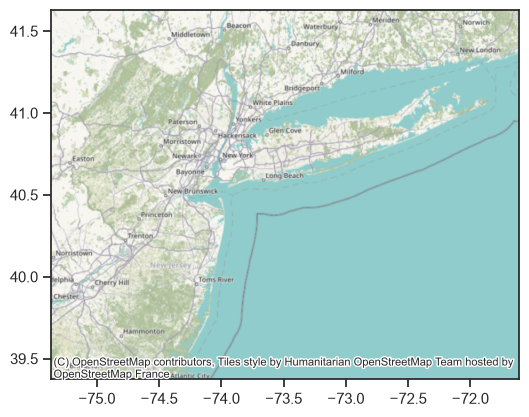

In [17]:
ax = gbg.boundary.plot(linewidth=.0, color="lightgrey")
sns.scatterplot(
    pois.filter(pl.col.ID_STORE == '8275101').to_pandas(),
    x="LONGITUDE",
    y="LATITUDE",
    ax=ax,
    zorder=10
)
cx.add_basemap(ax, crs="EPSG:4236")

In [18]:
pois.filter(pl.col.ID_STORE == "8275101")

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",f64,u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64


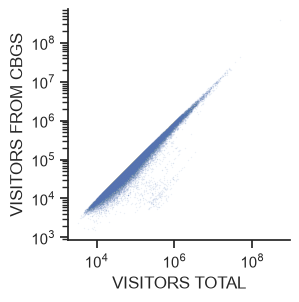

In [19]:
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(
    pois.to_pandas(),
    x="VISITORS",
    y="TOTAL_VISITORS",
    alpha=.1,
    s=1,
    ax=ax
)
vals = pois.to_pandas()[["VISITORS", "TOTAL_VISITORS"]]
lo = vals[vals > 0].min().min()
hi = vals.max().max()
lims = (10 ** np.floor(np.log10(lo)), 10 ** np.ceil(np.log10(hi)))
ticks = 10 ** np.arange(np.log10(lims[0]), np.log10(lims[1]) + 1)
ax.set(
    xlabel="VISITORS TOTAL",
    ylabel="VISITORS FROM CBGS",
    xticks=ticks,
    yticks=ticks,
    xscale="log",
    yscale="log",
)
ax.set_aspect('equal', adjustable='box')
sns.despine()

In [20]:
bg_dist = con.sql("""
    select v.ID_STORE, HOME_GEOID, SUM(VISITOR_COUNTS) AS VISITOR_COUNTS, COUNT(*) AS NUM_WEEKS
    from block_group_visits v
    join pois p on v.ID_STORE = p.ID_STORE
    where p.CBSAFP = '35620'
    group by v.ID_STORE, HOME_GEOID
""").pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:04<00:00,  1.24it/s]


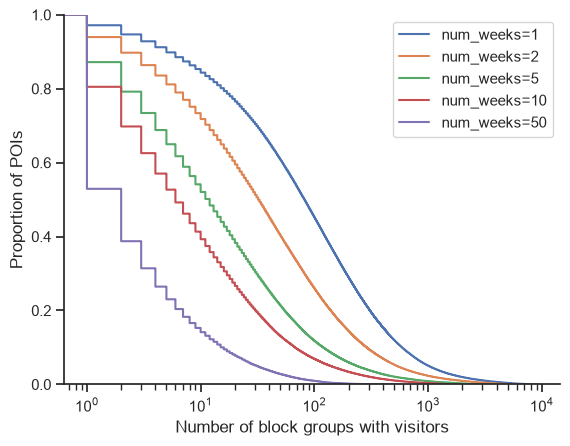

In [21]:
fig, ax = plt.subplots()
for t in tqdm([1, 2, 5, 10, 50]):
    d = bg_dist.filter(pl.col("NUM_WEEKS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"num_weeks={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with visitors")
ax.legend()
sns.despine()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:04<00:00,  1.25it/s]


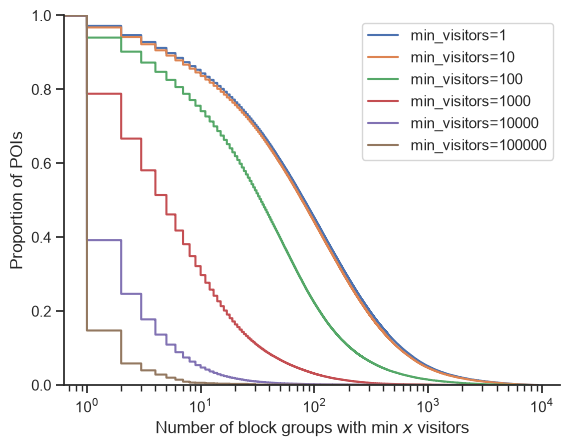

In [22]:
fig, ax = plt.subplots()
for t in tqdm([1, 10, 100, 1_000, 10_000, 100_000]):
    d = bg_dist.filter(pl.col("VISITOR_COUNTS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"min_visitors={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with min $x$ visitors")
ax.legend()
sns.despine()

In [23]:
query = """
with x as (
    select
        v.ID_STORE, HOME_GEOID,
        SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
        COUNT(*) AS NUM_WEEKS
    from block_group_visits v
    join pois p on v.ID_STORE = p.ID_STORE
    where VISITOR_COUNTS >= 10
      and cbsafp = '35620'
    group by v.ID_STORE, HOME_GEOID
)
select 
    ID_STORE, COUNT(*) AS NUM_BGS
from x
where NUM_WEEKS >= 5
  and VISITOR_COUNTS >= 100
group by ID_STORE
"""
test_data = con.sql(query).pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/var/folders/2r/78dg63lx1vg81rz95pp5vkj00000gp/T/ipykernel_70744/4225440880.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


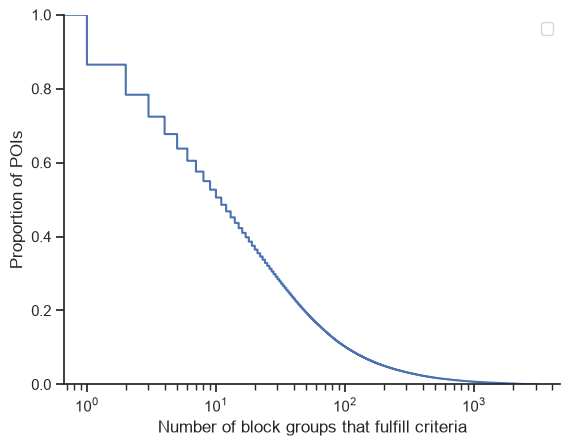

In [24]:
fig, ax = plt.subplots()
sns.ecdfplot(test_data["NUM_BGS"], complementary=True)
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups that fulfill criteria")
ax.legend()
sns.despine()

In [25]:
con.close()